In [1]:

import torch
from mamba_ssm import Mamba

model = Mamba(d_model=64, d_state=16, d_conv=4, expand=2).cuda()
x = torch.randn(2, 128, 64).cuda()
y = model(x)
print("Forward pass works:", y.shape)


Forward pass works: torch.Size([2, 128, 64])


In [2]:
import torch
import cv2
import albumentations
import matplotlib
import numpy
print("All good.")

All good.


In [2]:
import os
import tarfile

# Paths
base_path = "dataset/"

test_tar_path = os.path.join(base_path, "DFUC2022_test_release_new.tar")
train_tar_path = os.path.join(base_path, "DFUC2022_train_release.tar")

valid_extract_path = os.path.join(base_path, "valid")
train_extract_path = os.path.join(base_path, "training")

# Create destination folders
os.makedirs(valid_extract_path, exist_ok=True)
os.makedirs(train_extract_path, exist_ok=True)

# -----------------------------
# Extract TEST -> valid folder
# -----------------------------
print("Extracting test tar...")
with tarfile.open(test_tar_path, "r") as tar:
    tar.extractall(path=valid_extract_path)

print("Test extraction complete.")

# -----------------------------
# Extract TRAIN -> train folder
# -----------------------------
print("Extracting train tar...")
with tarfile.open(train_tar_path, "r") as tar:
    tar.extractall(path=train_extract_path)

print("Train extraction complete.")

Extracting test tar...


/tmp/ipykernel_2841/1012296319.py:22: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=valid_extract_path)


Test extraction complete.
Extracting train tar...


/tmp/ipykernel_2841/1012296319.py:31: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=train_extract_path)


Train extraction complete.


In [3]:
import os
import cv2
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt

# ==========================================
# 0. SPEED OPTIMIZATIONS
# ==========================================
# Enable CuDNN benchmark for faster convolutions
torch.backends.cudnn.benchmark = True

# Try to import official CUDA Mamba. If it fails, fallback to pure PyTorch (slow).
try:
    from mamba_ssm import Mamba
    USE_FAST_MAMBA = True
except ImportError:
    USE_FAST_MAMBA = False
    import math
    import torch.nn.functional as F
    print("WARNING: mamba-ssm not found! Falling back to SLOW pure PyTorch Mamba.")
    print("Run: pip install mamba-ssm causal-conv1d")

# ==========================================
# 1. DATASET & AUGMENTATION (Optimized I/O)
# ==========================================
class DFUDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_names, transform=None):
        self.transform = transform
        self.samples = []
        
        # Pre-calculate all valid paths ONCE to prevent disk I/O bottleneck
        for name in image_names:
            img_path = os.path.join(image_dir, name)
            if os.path.getsize(img_path) > 0:
                mask_path_jpg = os.path.join(mask_dir, name)
                mask_path_png = os.path.join(mask_dir, name.rsplit('.', 1)[0] + '.png')
                
                valid_mask_path = mask_path_png if os.path.exists(mask_path_png) else (mask_path_jpg if os.path.exists(mask_path_jpg) else None)
                self.samples.append({'img': img_path, 'mask': valid_mask_path})

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]
        image = cv2.imread(sample['img'])
        
        if image is not None:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        else:
            image = np.zeros((256, 256, 3), dtype=np.uint8)
        
        if sample['mask'] is not None:
            mask = cv2.imread(sample['mask'], cv2.IMREAD_GRAYSCALE)
        else:
            mask = np.zeros(image.shape[:2], dtype=np.uint8)

        mask = (mask > 127).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask'].unsqueeze(0)
            
        return image, mask

def get_train_transforms():
    return A.Compose([
        A.Resize(256, 256),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Affine(scale=(0.9, 1.1), translate_percent=(-0.0625, 0.0625), rotate=(-45, 45), p=0.5),
        A.CLAHE(p=0.3),
        A.RandomBrightnessContrast(p=0.3),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])

def get_val_transforms():
    return A.Compose([
        A.Resize(256, 256),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])

# ==========================================
# 2. FAST METRICS (Micro-Average Aggregation)
# ==========================================
def calculate_intersection_union(pred, target, threshold=0.5):
    """Calculates raw intersection and union for mathematically correct epoch averaging."""
    pred = (torch.sigmoid(pred) > threshold).float()
    
    intersection = (pred * target).sum().item()
    union = pred.sum().item() + target.sum().item()
    
    return intersection, union

# ==========================================
# 3. LOSS FUNCTIONS
# ==========================================
class FocalTverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, gamma=0.75, smooth=1e-3):
        super(FocalTverskyLoss, self).__init__()
        self.alpha, self.beta, self.gamma, self.smooth = alpha, beta, gamma, smooth

    def forward(self, inputs, targets):
        inputs = torch.sigmoid(inputs).view(-1)
        targets = targets.view(-1)
        
        tp = (inputs * targets).sum()
        fp = (inputs * (1 - targets)).sum()
        fn = ((1 - inputs) * targets).sum()
        
        tversky = (tp + self.smooth) / (tp + self.alpha * fp + self.beta * fn + self.smooth)
        return (1 - tversky) ** self.gamma

class CombinedLoss(nn.Module):
    def __init__(self):
        super(CombinedLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.tversky = FocalTverskyLoss()

    def forward(self, inputs, targets):
        return 0.5 * self.bce(inputs, targets) + 0.5 * self.tversky(inputs, targets)

# ==========================================
# 4. MAMBA & UNET++ BLOCKS (Bi-Directional)
# ==========================================
class FastMambaBlock(nn.Module):
    """Uses the official C++/CUDA Mamba implementation with a bi-directional 2D scan."""
    def __init__(self, d_model):
        super().__init__()
        self.mamba = Mamba(d_model=d_model, d_state=16, d_conv=4, expand=2)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        B, C, H, W = x.shape
        
        # Flatten image into a sequence (Forward Scan)
        x_fwd = x.view(B, C, -1).transpose(1, 2) # (B, L, C)
        
        # Reverse the sequence (Backward Scan)
        x_bwd = torch.flip(x_fwd, dims=[1])
        
        # Pass both through the Mamba block
        out_fwd = self.mamba(self.norm(x_fwd))
        out_bwd = torch.flip(self.mamba(self.norm(x_bwd)), dims=[1]) # Flip backward scan back to normal
        
        # Merge representations to give the model 2D spatial awareness
        out_merged = (out_fwd + out_bwd) / 2.0
        
        # Reshape back to image format
        out = out_merged.transpose(1, 2).view(B, C, H, W)
        return out + x

# Fallback PyTorch Mamba (kept original for safety)
class PurePyTorchMambaBlock(nn.Module):
    def __init__(self, d_model, d_state=16, d_conv=4, expand=2):
        super().__init__()
        self.d_model = d_model
        self.expand = expand
        self.d_inner = int(self.expand * self.d_model)
        self.norm = nn.LayerNorm(self.d_model)
        self.in_proj = nn.Linear(self.d_model, self.d_inner * 2, bias=False)
        self.conv1d = nn.Conv1d(in_channels=self.d_inner, out_channels=self.d_inner, bias=True, kernel_size=d_conv, groups=self.d_inner, padding=d_conv - 1)
        self.activation = nn.SiLU()
        self.x_proj = nn.Linear(self.d_inner, d_state * 2 + 1, bias=False)
        self.dt_proj = nn.Linear(1, self.d_inner, bias=True)
        A = torch.arange(1, d_state + 1, dtype=torch.float32).repeat(self.d_inner, 1)
        self.A_log = nn.Parameter(torch.log(A))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, self.d_model, bias=False)

    def forward(self, x_in):
        with torch.amp.autocast('cuda', enabled=False):
            x = x_in.float() 
            B, C, H, W = x.shape
            x_flat = x.flatten(2).transpose(1, 2)
            L = x_flat.size(1)
            x_norm = self.norm(x_flat)
            xz = self.in_proj(x_norm)
            x_proj, z = xz.chunk(2, dim=-1)
            x_conv = self.activation(self.conv1d(x_proj.transpose(1, 2))[:, :, :L].transpose(1, 2))
            x_state_proj = self.x_proj(x_conv)
            dt, B_state, C_state = torch.split(x_state_proj, [1, 16, 16], dim=-1)
            dt = torch.clamp(F.softplus(self.dt_proj(dt)), min=0.001, max=0.1)
            A = torch.clamp(-torch.exp(self.A_log.float()), min=-100.0, max=-1e-4)
            dA = torch.exp(torch.einsum('bld,dn->bldn', dt, A))
            dB = torch.einsum('bld,bln->bldn', dt, B_state)
            
            h = torch.zeros(B, self.d_inner, 16, device=x.device, dtype=torch.float32)
            ys = []
            for i in range(L): 
                h = dA[:, i] * h + dB[:, i] * x_conv[:, i].unsqueeze(-1)
                ys.append(torch.einsum('bdn,bn->bd', h, C_state[:, i]))
            
            y = torch.stack(ys, dim=1) + x_conv * self.D.float()
            out = self.out_proj(y * self.activation(z)) + x_flat
            return out.transpose(1, 2).view(B, C, H, W).to(x_in.dtype)

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.GELU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
    def forward(self, x):
        return self.conv(x)

class MambaUNetPlusPlus(nn.Module):
    def __init__(self, in_channels=3, num_classes=1, deep_supervision=True):
        super(MambaUNetPlusPlus, self).__init__()
        self.deep_supervision = deep_supervision
        nb_filter = [32, 64, 128, 256, 512]
        self.pool = nn.MaxPool2d(2, 2)
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        
        MambaLayer = FastMambaBlock if USE_FAST_MAMBA else PurePyTorchMambaBlock
        
        self.conv0_0 = ConvBlock(in_channels, nb_filter[0])
        self.conv1_0 = ConvBlock(nb_filter[0], nb_filter[1])
        self.conv2_0 = ConvBlock(nb_filter[1], nb_filter[2])
        self.conv3_0 = nn.Sequential(ConvBlock(nb_filter[2], nb_filter[3]), MambaLayer(nb_filter[3]))
        self.conv4_0 = nn.Sequential(ConvBlock(nb_filter[3], nb_filter[4]), MambaLayer(nb_filter[4]))
        
        self.conv0_1 = ConvBlock(nb_filter[0] + nb_filter[1], nb_filter[0])
        self.conv1_1 = ConvBlock(nb_filter[1] + nb_filter[2], nb_filter[1])
        self.conv2_1 = ConvBlock(nb_filter[2] + nb_filter[3], nb_filter[2])
        self.conv3_1 = ConvBlock(nb_filter[3] + nb_filter[4], nb_filter[3])
        self.conv0_2 = ConvBlock(nb_filter[0]*2 + nb_filter[1], nb_filter[0])
        self.conv1_2 = ConvBlock(nb_filter[1]*2 + nb_filter[2], nb_filter[1])
        self.conv2_2 = ConvBlock(nb_filter[2]*2 + nb_filter[3], nb_filter[2])
        self.conv0_3 = ConvBlock(nb_filter[0]*3 + nb_filter[1], nb_filter[0])
        self.conv1_3 = ConvBlock(nb_filter[1]*3 + nb_filter[2], nb_filter[1])
        self.conv0_4 = ConvBlock(nb_filter[0]*4 + nb_filter[1], nb_filter[0])
        
        if self.deep_supervision:
            self.final1 = nn.Conv2d(nb_filter[0], num_classes, kernel_size=1)
            self.final2 = nn.Conv2d(nb_filter[0], num_classes, kernel_size=1)
            self.final3 = nn.Conv2d(nb_filter[0], num_classes, kernel_size=1)
            self.final4 = nn.Conv2d(nb_filter[0], num_classes, kernel_size=1)
        else:
            self.final = nn.Conv2d(nb_filter[0], num_classes, kernel_size=1)

    def forward(self, input):
        x0_0 = self.conv0_0(input)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x0_1 = self.conv0_1(torch.cat([x0_0, self.up(x1_0)], 1))
        x2_0 = self.conv2_0(self.pool(x1_0))
        x1_1 = self.conv1_1(torch.cat([x1_0, self.up(x2_0)], 1))
        x0_2 = self.conv0_2(torch.cat([x0_0, x0_1, self.up(x1_1)], 1))
        x3_0 = self.conv3_0(self.pool(x2_0))
        x2_1 = self.conv2_1(torch.cat([x2_0, self.up(x3_0)], 1))
        x1_2 = self.conv1_2(torch.cat([x1_0, x1_1, self.up(x2_1)], 1))
        x0_3 = self.conv0_3(torch.cat([x0_0, x0_1, x0_2, self.up(x1_2)], 1))
        x4_0 = self.conv4_0(self.pool(x3_0))
        x3_1 = self.conv3_1(torch.cat([x3_0, self.up(x4_0)], 1))
        x2_2 = self.conv2_2(torch.cat([x2_0, x2_1, self.up(x3_1)], 1))
        x1_3 = self.conv1_3(torch.cat([x1_0, x1_1, x1_2, self.up(x2_2)], 1))
        x0_4 = self.conv0_4(torch.cat([x0_0, x0_1, x0_2, x0_3, self.up(x1_3)], 1))
        
        if self.deep_supervision:
            return [self.final1(x0_1), self.final2(x0_2), self.final3(x0_3), self.final4(x0_4)]
        return self.final(x0_4)

# ==========================================
# 5. TRAINING LOOP & PLOTTING
# ==========================================
def plot_metrics(history):
    epochs = range(1, len(history['train_loss']) + 1)
    
    plt.figure(figsize=(12, 5))
    
    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label='Train Loss', color='red', marker='o')
    plt.title('Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    # Plot Dice & IoU
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['val_dice'], label='Val Dice', color='blue', marker='o')
    plt.plot(epochs, history['val_iou'], label='Val IoU', color='green', marker='s')
    plt.title('Validation Metrics')
    plt.xlabel('Epochs')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig('training_metrics.png')
    print("Saved training graphs to 'training_metrics.png'")
    plt.close()

def train_model():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Training on device: {device}")
    
    base_dir = 'dataset/training/DFUC2022_train_release'
    image_dir = os.path.join(base_dir, 'DFUC2022_train_images')
    mask_dir = os.path.join(base_dir, 'DFUC2022_train_masks')
    
    if not os.path.exists(image_dir):
        image_dir, mask_dir = base_dir, base_dir
        
    valid_ext = ('.png', '.jpg', '.jpeg')
    all_image_names = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(valid_ext)])
    
    if not all_image_names: raise ValueError(f"No images found in {image_dir}")
        
    random.seed(42)
    random.shuffle(all_image_names)
    split_idx = int(0.8 * len(all_image_names))
    
    train_dataset = DFUDataset(image_dir, mask_dir, all_image_names[:split_idx], transform=get_train_transforms())
    val_dataset = DFUDataset(image_dir, mask_dir, all_image_names[split_idx:], transform=get_val_transforms())
    
    # BATCH SIZE INCREASED for A40/A100 optimization
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=4, pin_memory=True)
    
    model = MambaUNetPlusPlus(deep_supervision=True).to(device)
    criterion = CombinedLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    
    epochs = 100
    # SCHEDULER FIXED to decay over total epochs instead of resetting at 50
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda')
    
    best_val_dice = 0.0
    patience_counter = 0
    
    # Dictionary to hold data for graphing
    history = {'train_loss': [], 'val_dice': [], 'val_iou': []}
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")
        
        for images, masks in pbar:
            images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = sum(criterion(out, masks) for out in outputs) / len(outputs)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            
            train_loss += loss.item()
            pbar.set_postfix({'loss': f"{loss.item():.4f}"})
            
        scheduler.step()
        epoch_loss = train_loss / len(train_loader)
        
        # Validation Phase
        model.eval()
        total_intersection, total_union = 0, 0
        
        with torch.no_grad():
            for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]"):
                images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    final_output = outputs[-1] if isinstance(outputs, list) else outputs
                    
                # MICRO-AVERAGE: Accumulate totals across the entire validation set
                batch_intersection, batch_union = calculate_intersection_union(final_output, masks)
                total_intersection += batch_intersection
                total_union += batch_union
                
        # Calculate final Dice and IoU for the epoch
        val_dice = (2. * total_intersection + 1e-6) / (total_union + 1e-6)
        val_iou = (total_intersection + 1e-6) / (total_union - total_intersection + 1e-6)
        
        history['train_loss'].append(epoch_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)
        
        print(f"Loss: {epoch_loss:.4f} | Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f}")
        
        # Save model & graphs
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(model.state_dict(), 'best_mamba_unetpp.pth')
            print("--> Saved Best Model!")
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= 15:
                print(f"Early stopping triggered at epoch {epoch+1}")
                break
                
        # Update graphs every epoch
        plot_metrics(history)

if __name__ == "__main__":
    train_model()

Training on device: cuda


Epoch 1/100 [Val]: 100%|██████████| 13/13 [00:03<00:00,  4.10it/s]


Loss: 0.7421 | Val Dice: 0.3667 | Val IoU: 0.2245
--> Saved Best Model!
Saved training graphs to 'training_metrics.png'


Epoch 2/100 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.61it/s]


Loss: 0.6983 | Val Dice: 0.3845 | Val IoU: 0.2380
--> Saved Best Model!
Saved training graphs to 'training_metrics.png'


Epoch 3/100 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.52it/s]


... (177 outputs left out)

Epoch 92/100 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.60it/s]


Loss: 0.2634 | Val Dice: 0.8269 | Val IoU: 0.7049
Saved training graphs to 'training_metrics.png'


Epoch 93/100 [Val]: 100%|██████████| 13/13 [00:02<00:00,  5.55it/s]

Loss: 0.2656 | Val Dice: 0.8258 | Val IoU: 0.7033
Early stopping triggered at epoch 93


Successfully loaded model weights!


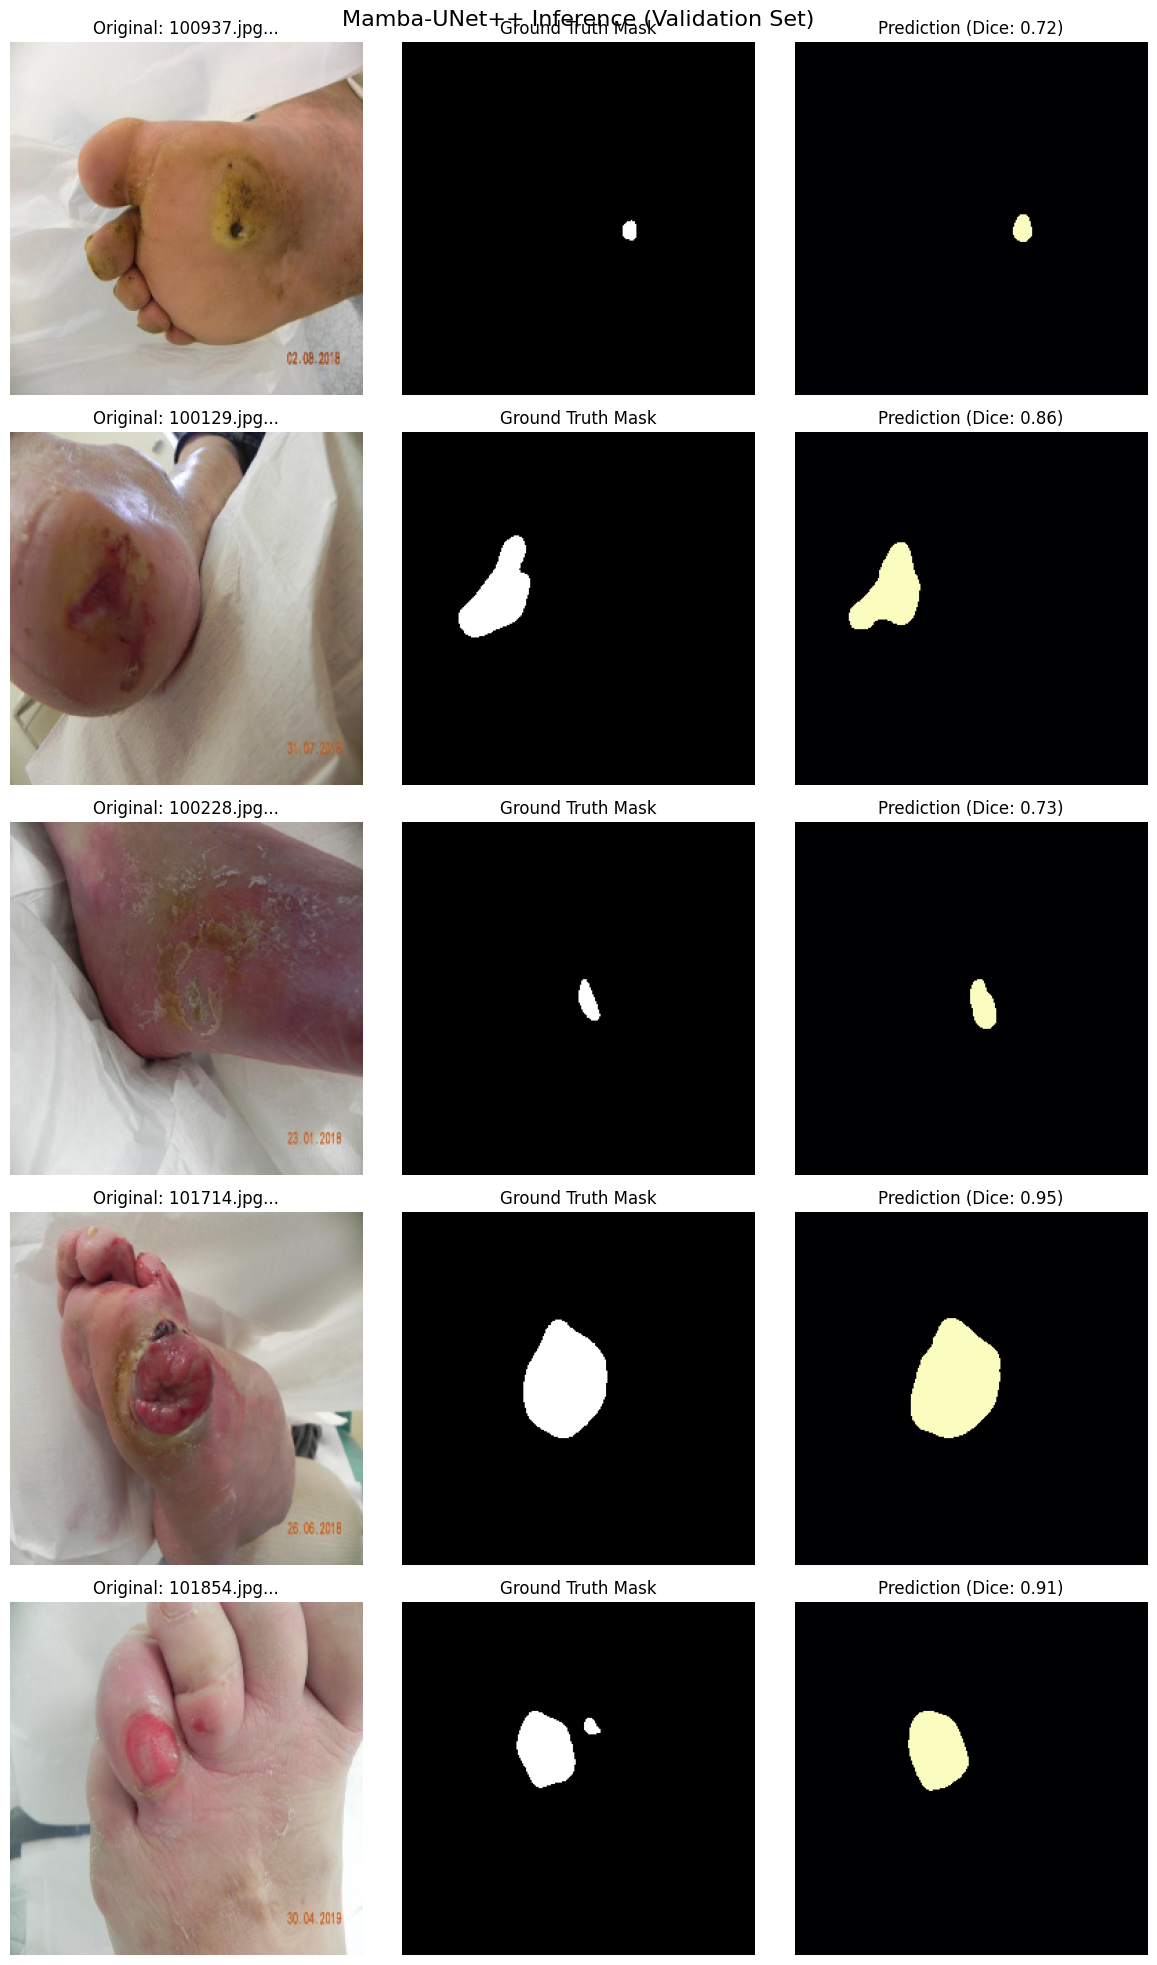

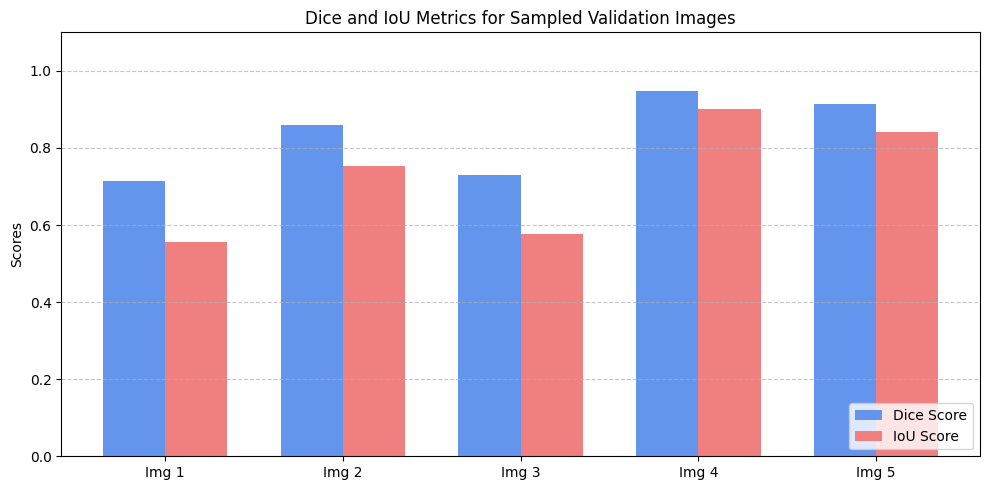

In [6]:
import os
import random
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURATION
# ==========================================
NUM_SAMPLES = 5  # How many random images to visualize
WEIGHTS_PATH = 'best_mamba_unetpp.pth'
VALID_BASE_DIR = 'dataset/training/DFUC2022_train_release'  # Adjust if your folder name is different

# Assuming standard DFU directory structure inside the valid folder
VALID_IMG_DIR = os.path.join(VALID_BASE_DIR, 'DFUC2022_train_images') 
VALID_MASK_DIR = os.path.join(VALID_BASE_DIR, 'DFUC2022_train_masks')

# If images and masks are just dumped in the base dir, fallback to base
if not os.path.exists(VALID_IMG_DIR):
    VALID_IMG_DIR, VALID_MASK_DIR = VALID_BASE_DIR, VALID_BASE_DIR

# ==========================================
# HELPER FUNCTIONS
# ==========================================
def calculate_single_metrics(pred_mask, true_mask):
    """Calculates Dice and IoU for a single 2D numpy array mask."""
    intersection = np.logical_and(pred_mask, true_mask).sum()
    union = np.logical_or(pred_mask, true_mask).sum()
    
    dice = (2. * intersection) / (pred_mask.sum() + true_mask.sum() + 1e-6)
    iou = intersection / (union + 1e-6)
    return dice, iou

# ==========================================
# INFERENCE & VISUALIZATION
# ==========================================
def run_inference_and_plot():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # 1. Load the Model
    model = MambaUNetPlusPlus(deep_supervision=True).to(device)
    model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device, weights_only=True))
    model.eval()
    print("Successfully loaded model weights!")

    # 2. Get random images
    valid_ext = ('.png', '.jpg', '.jpeg')
    all_images = [f for f in os.listdir(VALID_IMG_DIR) if f.lower().endswith(valid_ext)]
    
    if len(all_images) < NUM_SAMPLES:
        raise ValueError(f"Found fewer than {NUM_SAMPLES} images in {VALID_IMG_DIR}")
        
    sampled_images = random.sample(all_images, NUM_SAMPLES)
    val_transforms = get_val_transforms() # Uses the function already defined in your notebook
    
    # Data storage for the graphs
    results_dice = []
    results_iou = []
    
    # Setup the plot for the masks (NUM_SAMPLES rows, 3 columns)
    fig, axes = plt.subplots(NUM_SAMPLES, 3, figsize=(12, 4 * NUM_SAMPLES))
    fig.suptitle(f'Mamba-UNet++ Inference (Validation Set)', fontsize=16)
    
    with torch.no_grad():
        for i, img_name in enumerate(sampled_images):
            # Load Original Image
            img_path = os.path.join(VALID_IMG_DIR, img_name)
            image_bgr = cv2.imread(img_path)
            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            
            # Load True Mask
            mask_path_jpg = os.path.join(VALID_MASK_DIR, img_name)
            mask_path_png = os.path.join(VALID_MASK_DIR, img_name.rsplit('.', 1)[0] + '.png')
            valid_mask_path = mask_path_png if os.path.exists(mask_path_png) else mask_path_jpg
            
            if os.path.exists(valid_mask_path):
                true_mask = cv2.imread(valid_mask_path, cv2.IMREAD_GRAYSCALE)
                true_mask = (true_mask > 127).astype(np.float32)
            else:
                true_mask = np.zeros((256, 256), dtype=np.float32)

            # Apply Transforms (Resize and Normalize)
            augmented = val_transforms(image=image_rgb, mask=true_mask)
            tensor_img = augmented['image'].unsqueeze(0).to(device, non_blocking=True)
            tensor_mask = augmented['mask'].numpy() # Ground truth for metric calc
            
            # Forward Pass
            with torch.amp.autocast('cuda'):
                outputs = model(tensor_img)
                # Deep supervision returns a list, we want the final output
                final_output = outputs[-1] if isinstance(outputs, list) else outputs
                
            # Convert logits to binary mask map
            pred_probs = torch.sigmoid(final_output).squeeze().cpu().numpy()
            pred_binary = (pred_probs > 0.5).astype(np.float32)
            
            # Calculate Metrics
            dice, iou = calculate_single_metrics(pred_binary, tensor_mask)
            results_dice.append(dice)
            results_iou.append(iou)
            
            # Plotting Images
            # Original Image (need to un-normalize for viewing)
            mean = np.array([0.485, 0.456, 0.406])
            std = np.array([0.229, 0.224, 0.225])
            view_img = tensor_img.squeeze().cpu().numpy().transpose(1, 2, 0)
            view_img = std * view_img + mean
            view_img = np.clip(view_img, 0, 1)

            axes[i, 0].imshow(view_img)
            axes[i, 0].set_title(f"Original: {img_name[:10]}...")
            axes[i, 0].axis('off')
            
            axes[i, 1].imshow(tensor_mask, cmap='gray')
            axes[i, 1].set_title("Ground Truth Mask")
            axes[i, 1].axis('off')
            
            axes[i, 2].imshow(pred_binary, cmap='magma') # Magma makes the predictions pop visually
            axes[i, 2].set_title(f"Prediction (Dice: {dice:.2f})")
            axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

    # ==========================================
    # PLOT METRICS BAR CHART
    # ==========================================
    x = np.arange(NUM_SAMPLES)
    width = 0.35

    fig2, ax = plt.subplots(figsize=(10, 5))
    rects1 = ax.bar(x - width/2, results_dice, width, label='Dice Score', color='cornflowerblue')
    rects2 = ax.bar(x + width/2, results_iou, width, label='IoU Score', color='lightcoral')

    ax.set_ylabel('Scores')
    ax.set_title('Dice and IoU Metrics for Sampled Validation Images')
    ax.set_xticks(x)
    ax.set_xticklabels([f"Img {i+1}" for i in range(NUM_SAMPLES)])
    ax.legend(loc='lower right')
    ax.set_ylim([0, 1.1])
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Run it!
run_inference_and_plot()